In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from seaborn import heatmap
import matplotlib.pyplot as plt
from itertools import combinations
import statsmodels.api as sm

In [2]:
sector_list = {}
sector_list["MAGS7"] = ['AAPL', 'MSFT', 'GOOG', 'NVDA', 'TSLA', 'META', 'AMZN']
sector_list["Tech"] = ['AVGO', 'ACN', 'ADBE', 'AMAT', 'AMD', 'CRM', 'CSCO', 'IBM', 'INTC', 'INTU', 'MU', 'ORCL', 'QCOM', 'TXN']
sector_list["HeathCare"] = ['ABBV', 'ABT', 'AMGN', 'BIIB', 'BMY', 'CVS', 'GILD', 'ISRG', 'JNJ', 'LLY', 'MDT', 'MRK', 'PFE', 'TMO', 'UNH', 'WBA']
sector_list["Financials"] = ['AIG', 'AXP', 'BAC', 'BRK', 'C', 'GS', 'JPM', 'MA', 'PYPL', 'SCHW', 'USB', 'V', 'WFC']
sector_list["ConsumerDiscretionary"] = ["BKNG", 'EBAY', 'HD', 'LOW', 'MCD', 'SBUX']
sector_list["ConsumerStaples"] = ["COST", 'KO', 'MO', 'PEP', 'PG', 'PM', 'WMT']
sector_list["Industrials"] = ['BA', 'CAT', 'DE', 'GE', 'HON', 'LMT', 'MMM', 'RTX', 'UNP', 'UPS']
sector_list["Communication"] = ["CHTR", 'CMCSA', 'DIS', 'NFLX', 'T', 'VZ']
sector_list["Energy"] = ["COP", 'CVX', 'KMI', 'OXY', 'SLB', 'XOM']
stock_list = ["SPX"]
for key, val in sector_list.items():
    stock_list.extend(val)
    
vix = pd.read_csv("./VIX_Result/VIX.csv", index_col=0)
vix = vix.loc[:, stock_list]
vix.ffill(inplace=True)

In [3]:
from scipy.stats import rankdata
def get_rank_stock(x):
    x.loc[:, "rank"] = rankdata(x.loc[:, "weight"])
    return x

In [4]:
market_weights = pd.read_csv("./Market_weights/Market_weights.csv", index_col=0)
market_weights = market_weights.groupby("date2").apply(get_rank_stock)
market_weights = market_weights.droplevel(0)

In [5]:
market_weights

,ticker,in SPX,daily_price,weight,rank
date2,,,,,
2014-01-02,ORCL,True,37.84,0.005848,465.0
2014-01-02,MSFT,True,37.16,0.018409,498.0
2014-01-02,TROW,True,82.56,0.001302,312.0
2014-01-02,HON,True,90.32,0.004251,447.0
2014-01-02,EMC,True,25.07,0.003068,420.0
...,...,...,...,...,...
2024-12-31,DG,True,75.82,0.000327,100.0
2024-12-31,FTNT,True,94.48,0.001434,366.0
2024-12-31,GNRC,True,155.05,0.000181,20.0


In [6]:
for sector, component in sector_list.items():
    ticker_rank = []
    for ticker in component:
        mean_rank = np.mean(market_weights.loc[market_weights.ticker == ticker, "rank"])
        ticker_rank.append(mean_rank)
    
    unordered_stock = np.array(component)
    ordered_stock = unordered_stock[np.argsort(ticker_rank[::-1])]
    sector_list[sector] = ordered_stock

PLTR    697
UBER    344
DHR       9
MRNA    541
KHC      31

In [41]:
def egarch_loglik_0fac(params, vol):
    eps = 0
    sigma = np.std(vol[0:-1]-vol[1:])
    log_lik = 0
    
    for i in range(1, len(vol)):
        y = vol[i] - vol[i-1]
        mu = params[0] + params[1] * vol[i-1]
        sigma = (np.exp(params[2]+params[3]*np.abs(eps)+params[4]*eps+params[5]*np.log(sigma**2)))**0.5
        eps = (y - mu)/sigma
        log_lik += (-np.log(sigma) - 0.5 * ((y-mu)/sigma)**2)

    return -log_lik

def get_standard_resid_0fac(params, vol):
    eps = [0]
    sigma = np.std(vol[0:-1]-vol[1:])
    for i in range(1, len(vol)):
        y = vol[i] - vol[i-1]
        mu = params[0] + params[1] * vol[i-1]
        sigma = (np.exp(params[2] + params[3]*np.abs(eps[i-1]) + params[4]*eps[i-1] + params[5]*np.log(sigma**2)))**0.5
        eps.append((y - mu)/sigma) 
    
    return eps

def egarch_loglik_1fac(params, vol, vix):
    eps = 0
    sigma = np.std(vol[0:-1]-vol[1:])
    log_lik = 0

    for i in range(1, len(vol)):
        y = vol[i] - vol[i-1]
        mu = params[0] + params[1] * (vix[i] - vix[i-1]) + params[2] * vol[i-1] + params[3] * vix[i-1]
        sigma = (np.exp(params[4] + params[5]*np.abs(eps) + params[6]*eps + params[7]*np.log(sigma**2)))**0.5
        eps = (y - mu)/sigma
        log_lik += -0.5 * (np.log(sigma**2) + ((y-mu)/sigma)**2)
        
    return -log_lik

def get_standard_resid_1fac(params, vol, vix):
    eps = [0]
    sigma = np.std(vol[0:-1]-vol[1:])
    for i in range(1, len(vol)):
        y = vol[i] - vol[i-1]
        mu = params[0] + params[1] * (vix[i] - vix[i-1]) + params[2] * vol[i-1] + params[3] * vix[i-1]
        sigma = (np.exp(params[4] + params[5]*np.abs(eps[i-1]) + params[6]*eps[i-1] + params[7]*np.log(sigma**2)))**0.5
        eps.append((y - mu)/sigma) 
    
    return eps

def dcc_loglik(params, resid):
    # residual is T x k matrix, k is number of asset
    T = resid.shape[0]
    Q_bar = np.mean([np.outer(resid[t, :], resid[t, :]) for t in range(T)], axis=0)
    Q = Q_bar.copy()
    log_lik = 0
    for t in range(1, T):
        eps_sq = np.outer(resid[t-1, :], resid[t-1, :])
        Q = (1-params[0]-params[1]) * Q_bar + params[0] * eps_sq + params[1] * Q
        Q_std = np.sqrt(np.diag(Q)).reshape(-1, 1)
        R = np.dot(np.dot(Q_std, Q), Q_std.T)
        print(Q_std.shape, Q.shape)
        R_det = np.linalg.det(R)
        R_inv = np.linalg.inv(R)
        if np.abs(R_det) < 0.001:
            loglik += 1e6
            
        loglik += -np.log(R_det) - np.dot(np.dot(resid[t-1, :], R_inv), resid[t-1, :].T)
        
    
    return -loglik

In [10]:
# 0 Factor
init_params_0fac = [0.01, 0.01, -0.5, 0.3, 0.05, 0.9]
params_0fac = {}
resid_0fac = {}
for ticker in vix.columns:
    print(ticker)
    if ticker != "SPX":
        log_vol = np.log(vix.loc[:, ticker].dropna().values)
        res = minimize(egarch_loglik_0fac, init_params_0fac, args=(log_vol), method='Nelder-Mead', tol=1e-4, 
                    bounds=[(None, None), (None, None), (None, None), (None, None), (None, None), (None, 0.995)], options={"maxiter":10000, "disp":True})
        params_0fac[ticker] = res.x
        resid_0fac[ticker] = get_standard_resid_0fac(res.x, log_vol)

# 1 factor
init_params_1fac = [-0.1, 0.3, -0.1, 0.01, -1, 0.3, 0.05, 0.9]
params_1fac = {}
resid_1fac = {}

for ticker in vix.columns:
    print(ticker)
    if ticker != "SPX":
        log_vol = np.log(vix.loc[:, ticker].dropna().values)
        log_vix = np.log(vix.loc[~vix.loc[:, ticker].isna(), "SPX"].values)
        res = minimize(egarch_loglik_1fac, init_params_1fac, args=(log_vol, log_vix), method='Nelder-Mead', tol=1e-4, 
                    bounds=[(None, None), (0, None), (None, None), (None, None), (None, None), (None, None), (None, None), (0, 0.995)], options={"maxiter":10000, "disp":True})
        params_1fac[ticker] = res.x
        resid_1fac[ticker] = get_standard_resid_1fac(res.x, log_vol, log_vix)

SPX
AAPL
Optimization terminated successfully.
         Current function value: -3160.201698
         Iterations: 636
         Function evaluations: 1002
MSFT
Optimization terminated successfully.
         Current function value: -3123.322479
         Iterations: 755
         Function evaluations: 1145
GOOG
Optimization terminated successfully.
         Current function value: -3046.445933
         Iterations: 556
         Function evaluations: 864
NVDA
Optimization terminated successfully.
         Current function value: -3376.919260
         Iterations: 469
         Function evaluations: 728
TSLA
Optimization terminated successfully.
         Current function value: -3269.491774
         Iterations: 886
         Function evaluations: 1389
META
Optimization terminated successfully.
         Current function value: -3162.436966
         Iterations: 855
         Function evaluations: 1282
AMZN
Optimization terminated successfully.
         Current function value: -3102.561213
         

/var/folders/ln/bzclmw8j1y9c2gkbs0pwhfkc0000gn/T/ipykernel_49907/4247003932.py:35: RuntimeWarning: divide by zero encountered in scalar divide
  eps = (y - mu)/sigma
/var/folders/ln/bzclmw8j1y9c2gkbs0pwhfkc0000gn/T/ipykernel_49907/4247003932.py:36: RuntimeWarning: divide by zero encountered in log
  log_lik += -0.5 * (np.log(sigma**2) + ((y-mu)/sigma)**2)
/var/folders/ln/bzclmw8j1y9c2gkbs0pwhfkc0000gn/T/ipykernel_49907/4247003932.py:36: RuntimeWarning: divide by zero encountered in scalar divide
  log_lik += -0.5 * (np.log(sigma**2) + ((y-mu)/sigma)**2)
/var/folders/ln/bzclmw8j1y9c2gkbs0pwhfkc0000gn/T/ipykernel_49907/4247003932.py:36: RuntimeWarning: invalid value encountered in scalar add
  log_lik += -0.5 * (np.log(sigma**2) + ((y-mu)/sigma)**2)
/var/folders/ln/bzclmw8j1y9c2gkbs0pwhfkc0000gn/T/ipykernel_49907/4247003932.py:34: RuntimeWarning: invalid value encountered in scalar add
  sigma = (np.exp(params[4] + params[5]*np.abs(eps) + params[6]*eps + params[7]*np.log(sigma**2)))**0.5

Optimization terminated successfully.
         Current function value: -3549.437198
         Iterations: 1482
         Function evaluations: 2220
EBAY
Optimization terminated successfully.
         Current function value: -3166.658908
         Iterations: 1070
         Function evaluations: 1597
HD
Optimization terminated successfully.
         Current function value: -3623.300092
         Iterations: 969
         Function evaluations: 1443
LOW
Optimization terminated successfully.
         Current function value: -3386.392488
         Iterations: 1388
         Function evaluations: 2072
MCD
Optimization terminated successfully.
         Current function value: -3419.700455
         Iterations: 934
         Function evaluations: 1381
SBUX
Optimization terminated successfully.
         Current function value: -3294.586721
         Iterations: 2057
         Function evaluations: 2997
COST
Optimization terminated successfully.
         Current function value: -3531.524925
         Iterati

In [42]:
init_params = [0.2, 0.8]
resids = np.vstack((resid_1fac["MSFT"], resid_1fac["AAPL"])).T
dcc_loglik(init_params, resids)

ValueError: shapes (2,1) and (2,2) not aligned: 1 (dim 1) != 2 (dim 0)

In [286]:
params_0fac = pd.DataFrame.from_dict(params_0fac, orient="columns")
params_0fac.mean(axis=1)

0    0.099620
1   -0.029115
2   -0.972638
3    0.196674
4    0.123441
5    0.846323
dtype: float64

<Axes: >

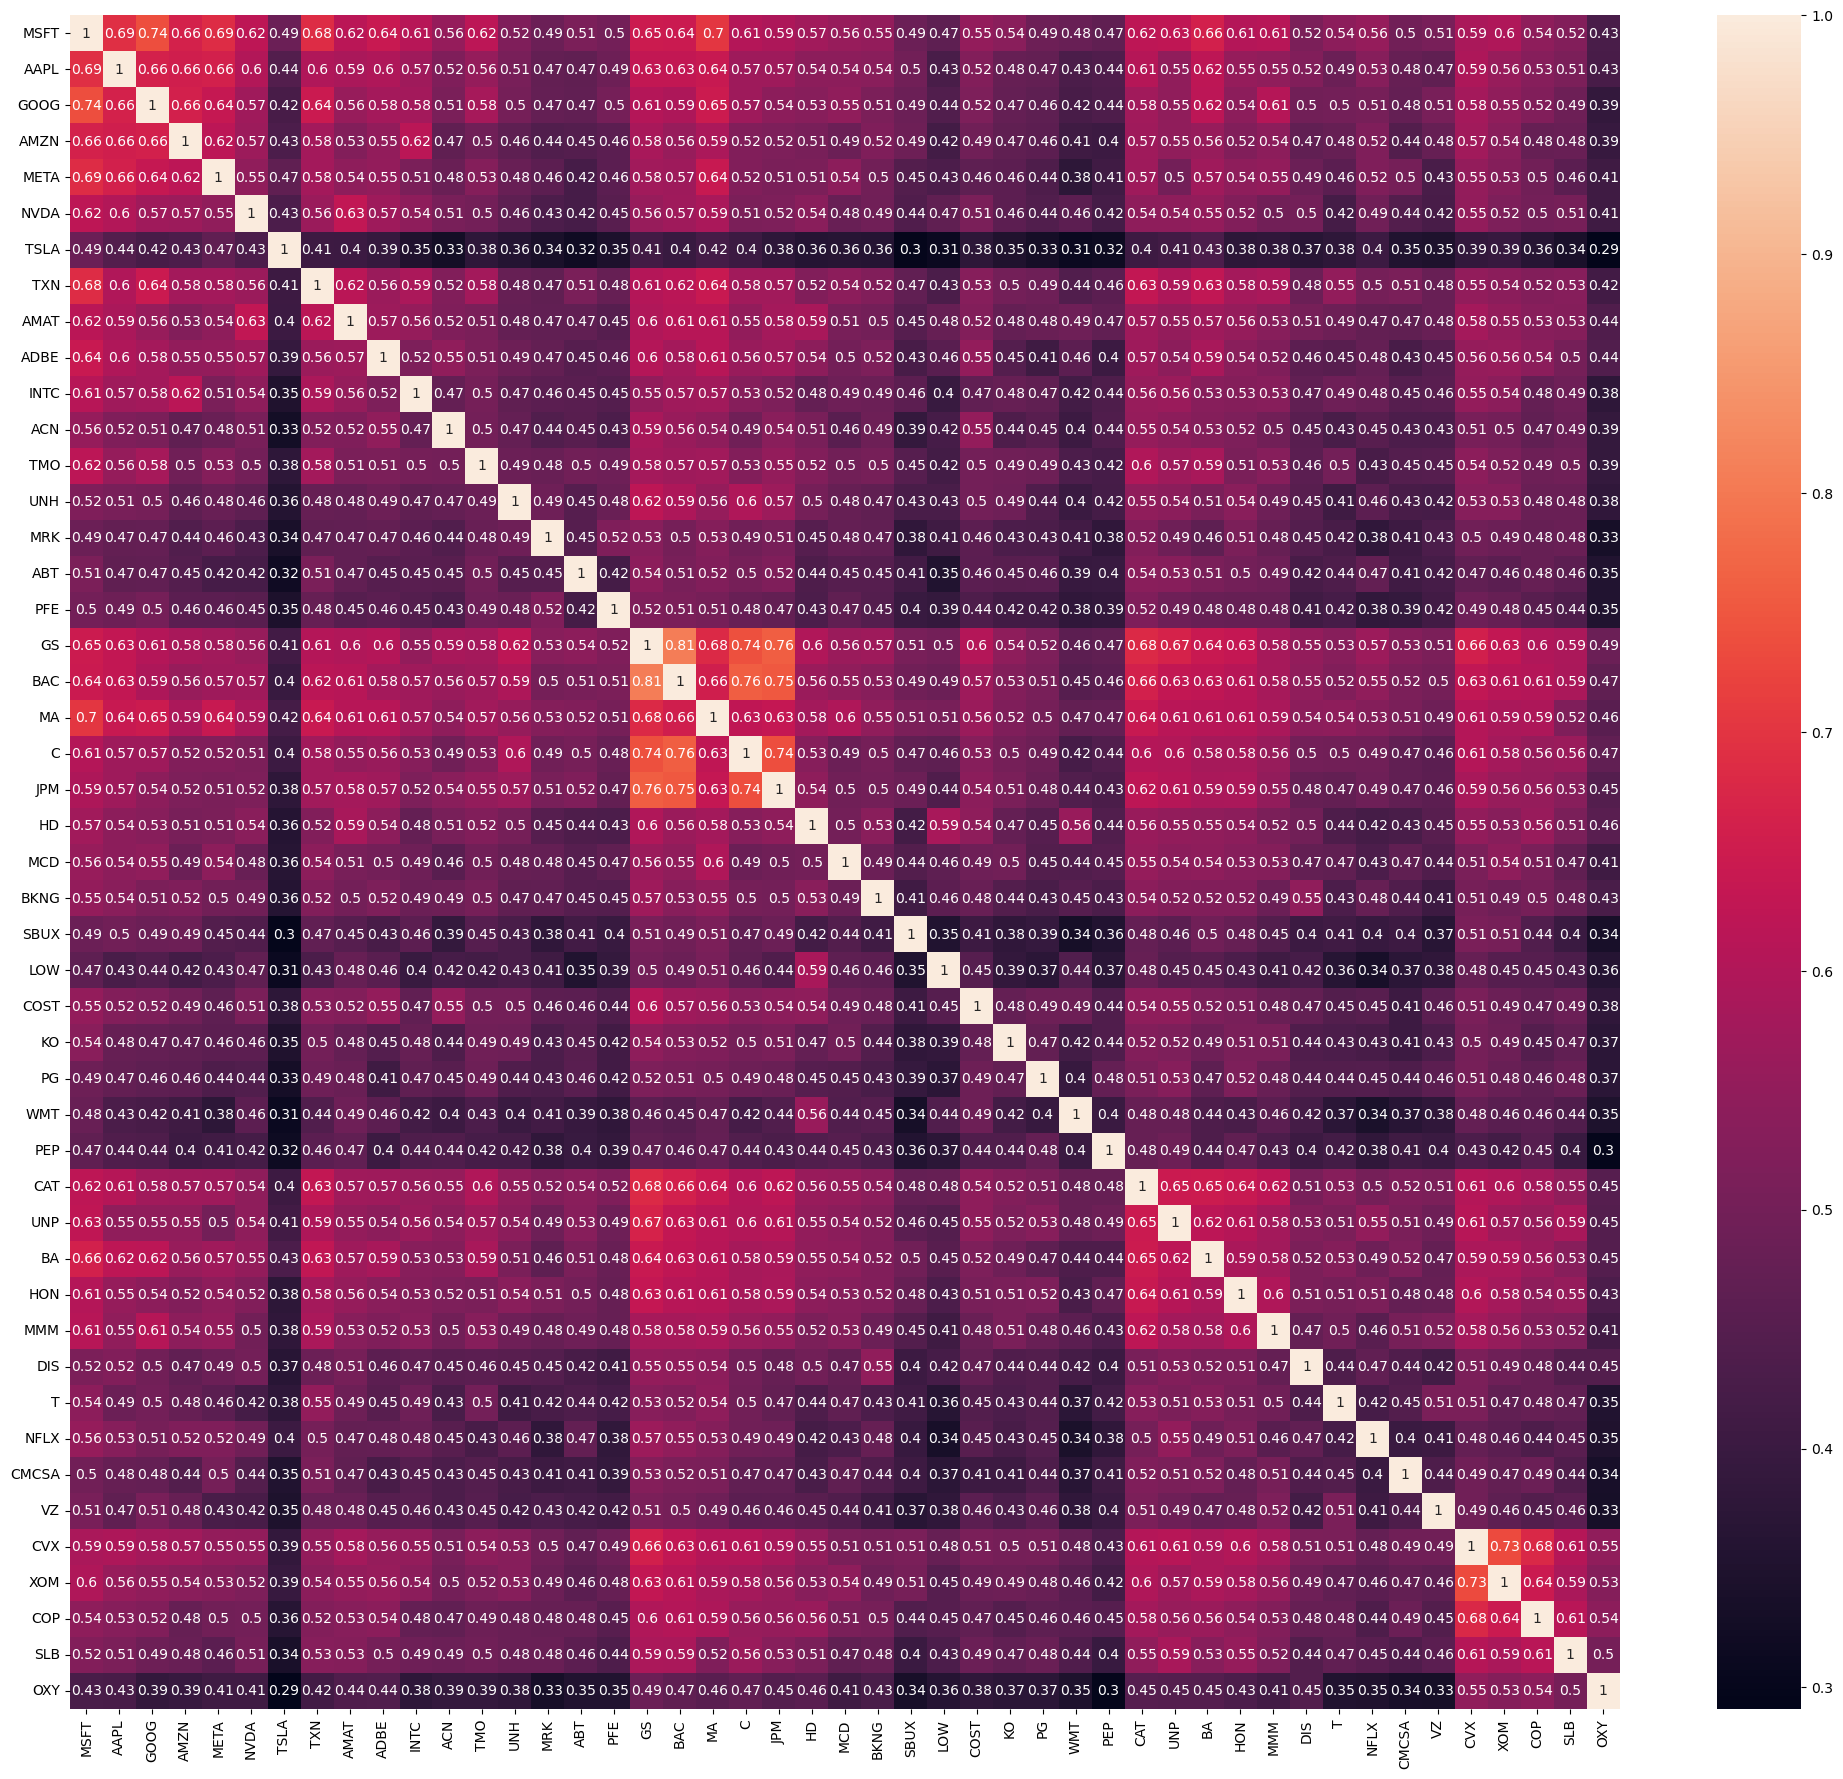

In [400]:
resid_0fac = pd.DataFrame.from_dict(resid_0fac, orient="columns")
resid_0fac_corr = resid_0fac.corr()
mean_corr = resid_0fac_corr.mean(axis=1)
col = resid_0fac_corr.columns
col_arrange = []
group_corr = []
for key, val in sector_list.items():
    if key == "MAGS7":
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index))
    else:
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index[:5]))
    
    within_grp_corr = np.mean(resid_0fac_corr.loc[val, val])
    inter_grp_corr = np.mean(resid_0fac_corr.loc[val, col[~np.isin(col, val)]])
    group_corr.append([key, within_grp_corr, inter_grp_corr])
plt.figure(figsize=(25, 22)) 
heatmap(resid_0fac_corr.loc[col_arrange, col_arrange], annot=True) 

In [401]:
group_corr = pd.DataFrame(group_corr, columns=["Sector", "Within_Group_Corr", "Inter_Group_Corr"])
group_corr

,Sector,Within_Group_Corr,Inter_Group_Corr
0,MAGS7,0.643685,0.466488
1,Tech,0.505412,0.439409
2,HeathCare,0.407240,0.392460
3,Financials,0.608728,0.470926
4,ConsumerDiscretionary,0.523468,0.426437
5,ConsumerStaples,0.490698,0.407677
6,Industrials,0.575906,0.463977
7,Communication,0.513006,0.421594
8,Energy,0.604909,0.440645


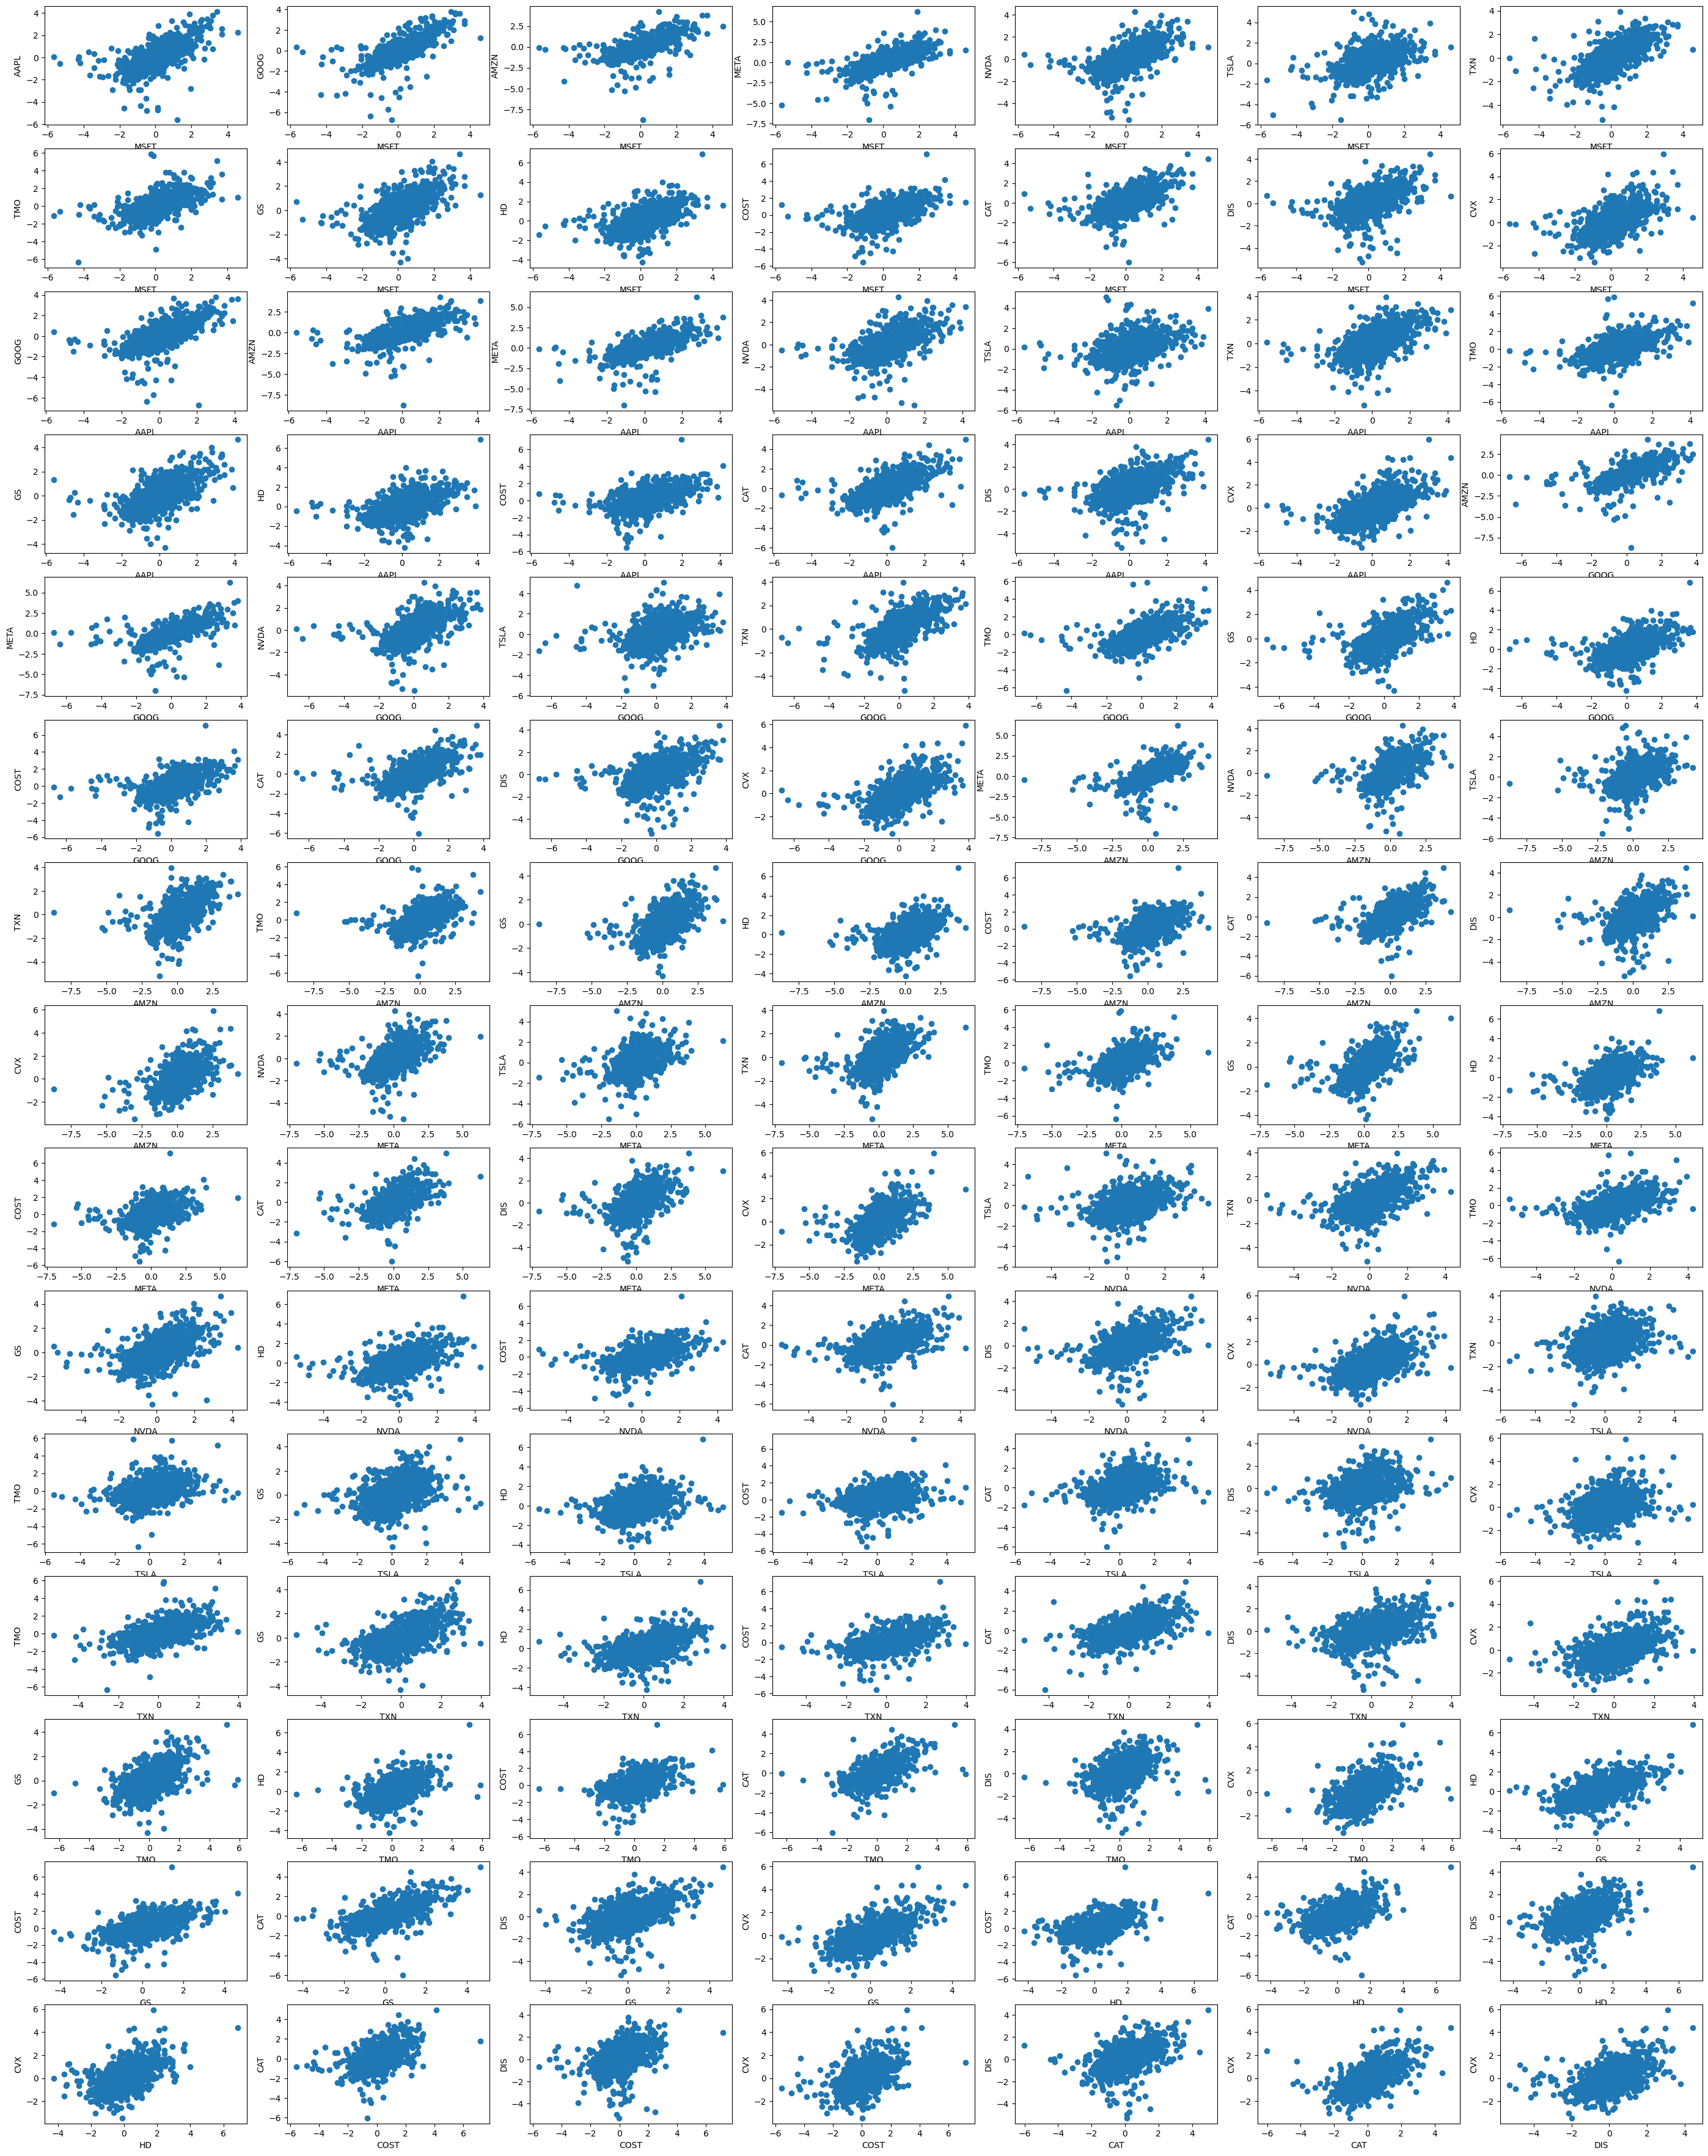

In [402]:
col_arrange = []
for key, val in sector_list.items():
    if key == "MAGS7":
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index))
    else:
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index[:1]))

fig, axs = plt.subplots(15, 7, figsize=(35, 45))
i, j = 0, 0
for ticker_1, ticker_2 in combinations(col_arrange, 2):
    axs[i, j].scatter(resid_0fac[[ticker_1]], resid_0fac[[ticker_2]])
    axs[i, j].set_xlabel(ticker_1)
    axs[i, j].set_ylabel(ticker_2)
    j += 1
    if j==7:
        i += 1
        j = 0

In [403]:
params_1fac = pd.DataFrame.from_dict(params_1fac, orient="columns")
params_1fac.mean(axis=1)

0    0.080560
1    0.474720
2   -0.050447
3    0.030787
4   -0.913381
5    0.212805
6    0.096019
7    0.869550
dtype: float64

<Axes: >

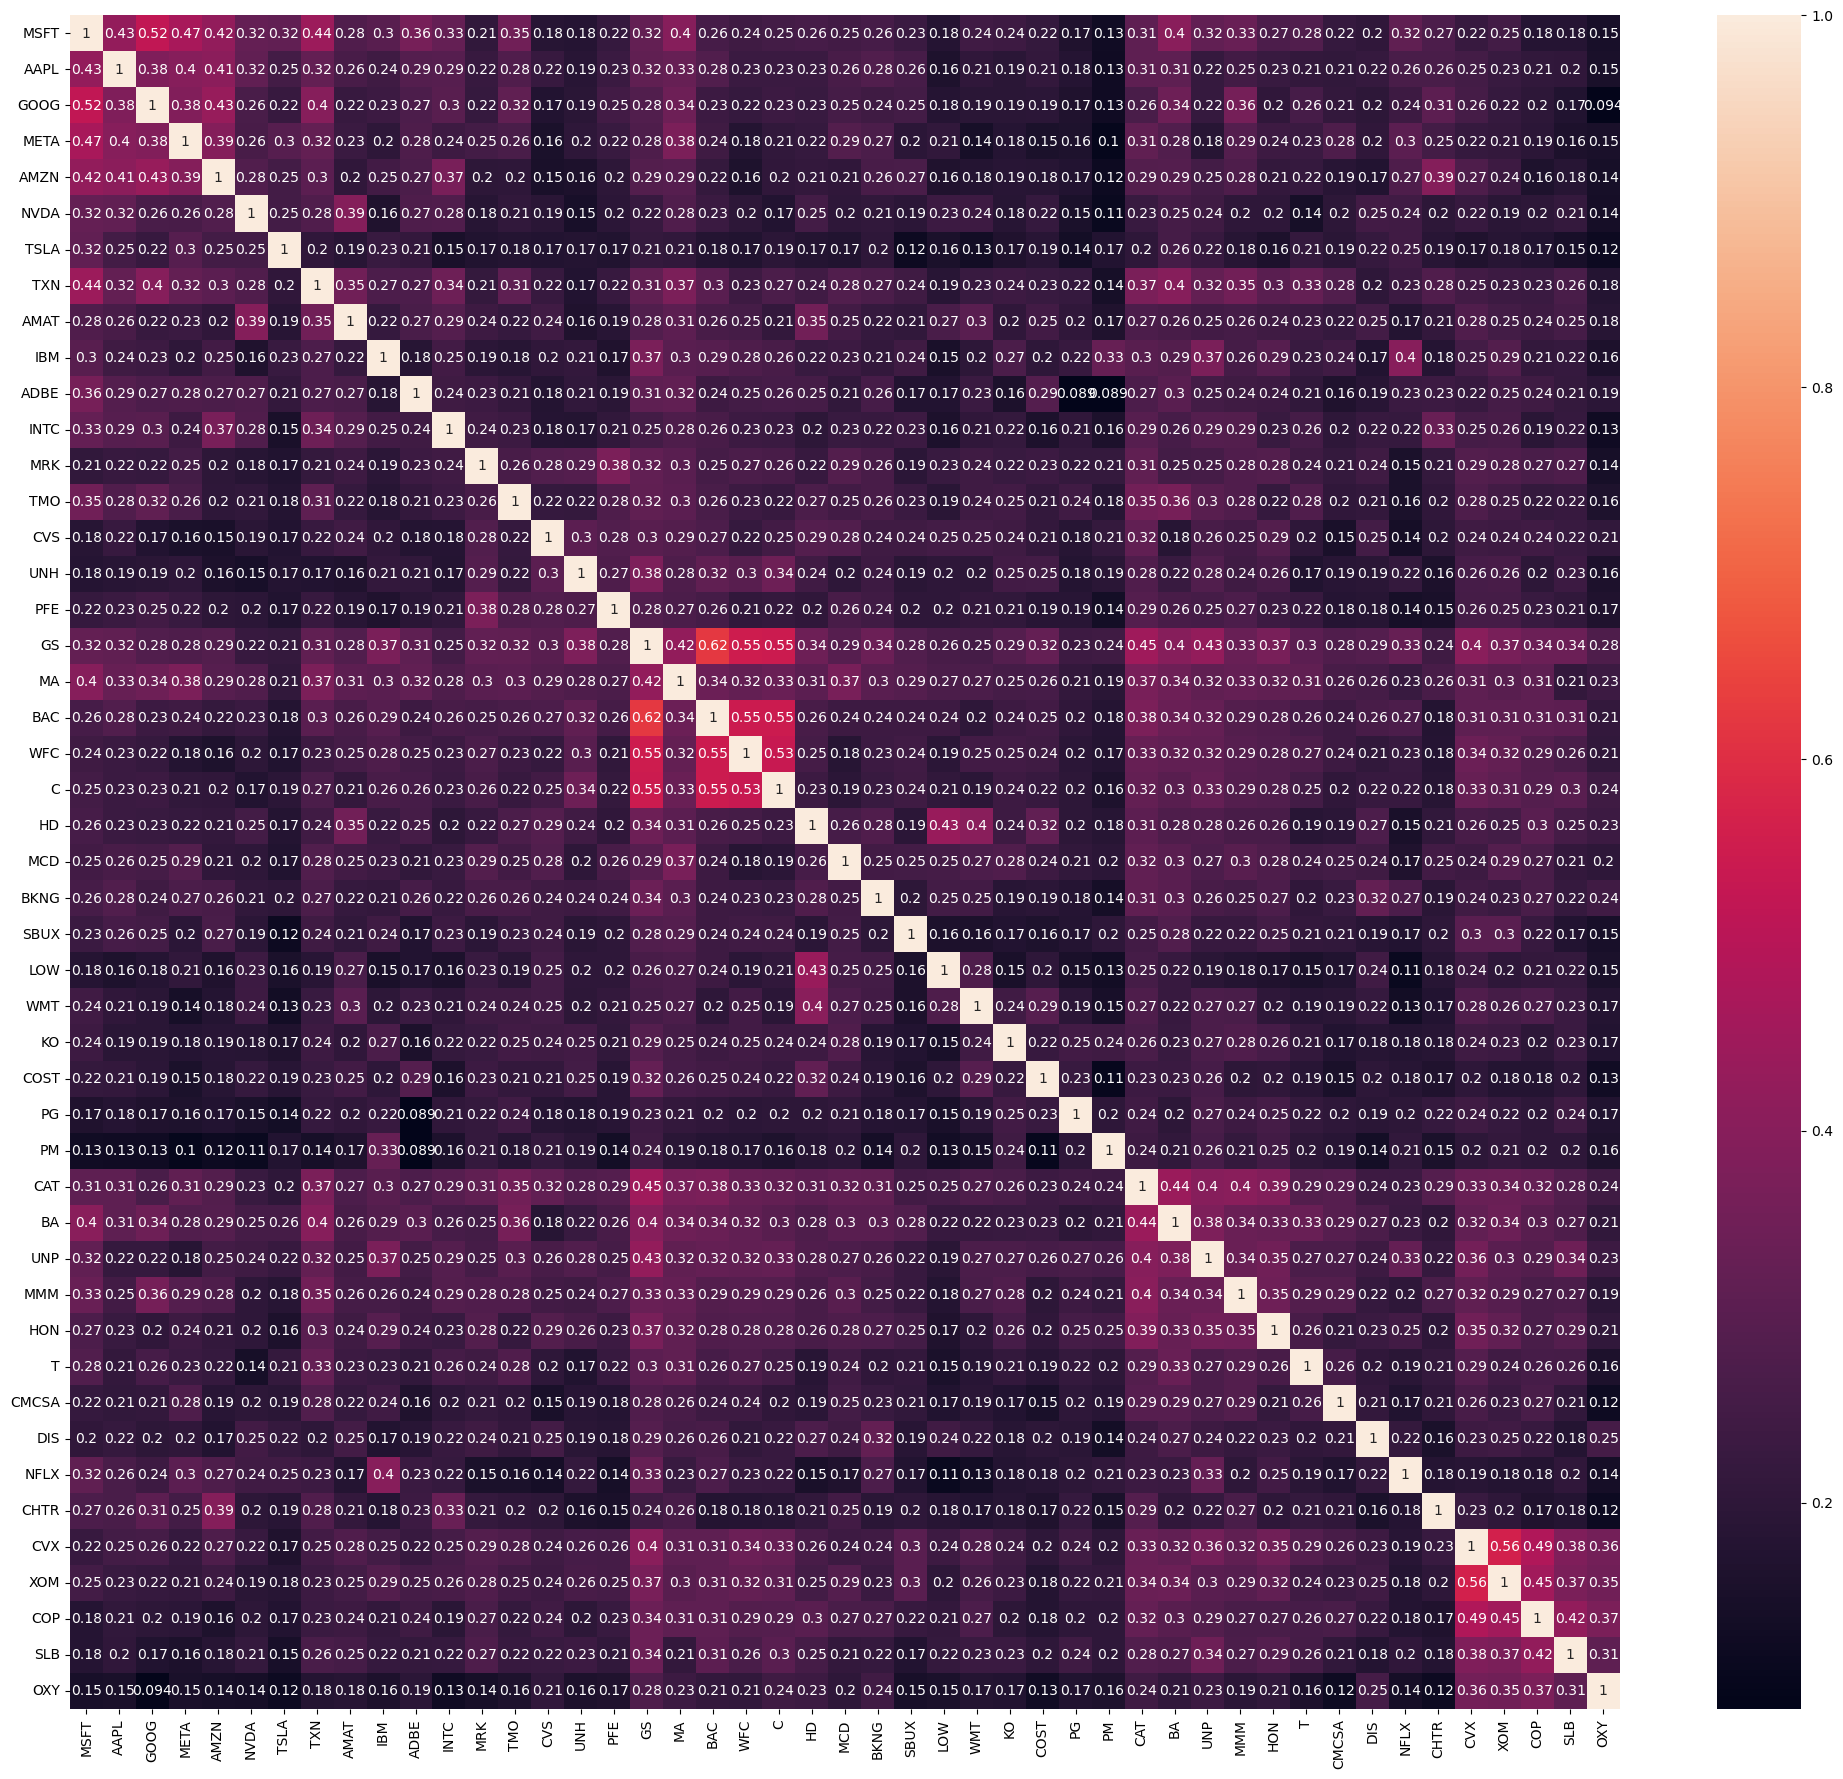

In [404]:
resid_1fac = pd.DataFrame.from_dict(resid_1fac, orient="columns")
resid_1fac_corr = resid_1fac.corr()
mean_corr = resid_1fac_corr.mean(axis=1)
col = resid_1fac_corr.columns
col_arrange = []
group_corr = []
for key, val in sector_list.items():
    if key == "MAGS7":
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index))
    else:
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index[:5]))
    
    within_grp_corr = np.mean(resid_1fac_corr.loc[val, val])
    inter_grp_corr = np.mean(resid_1fac_corr.loc[val, col[~np.isin(col, val)]])
    group_corr.append([key, within_grp_corr, inter_grp_corr])
    
plt.figure(figsize=(25, 22)) 
heatmap(resid_1fac_corr.loc[col_arrange, col_arrange], annot=True) 

In [405]:
group_corr = pd.DataFrame(group_corr, columns=["Sector", "Within_Group_Corr", "Inter_Group_Corr"])
group_corr

,Sector,Within_Group_Corr,Inter_Group_Corr
0,MAGS7,0.439621,0.207955
1,Tech,0.282229,0.199073
2,HeathCare,0.254448,0.188883
3,Financials,0.380195,0.220233
4,ConsumerDiscretionary,0.355472,0.205028
5,ConsumerStaples,0.317822,0.184105
6,Industrials,0.376380,0.229989
7,Communication,0.336431,0.197629
8,Energy,0.446130,0.204663


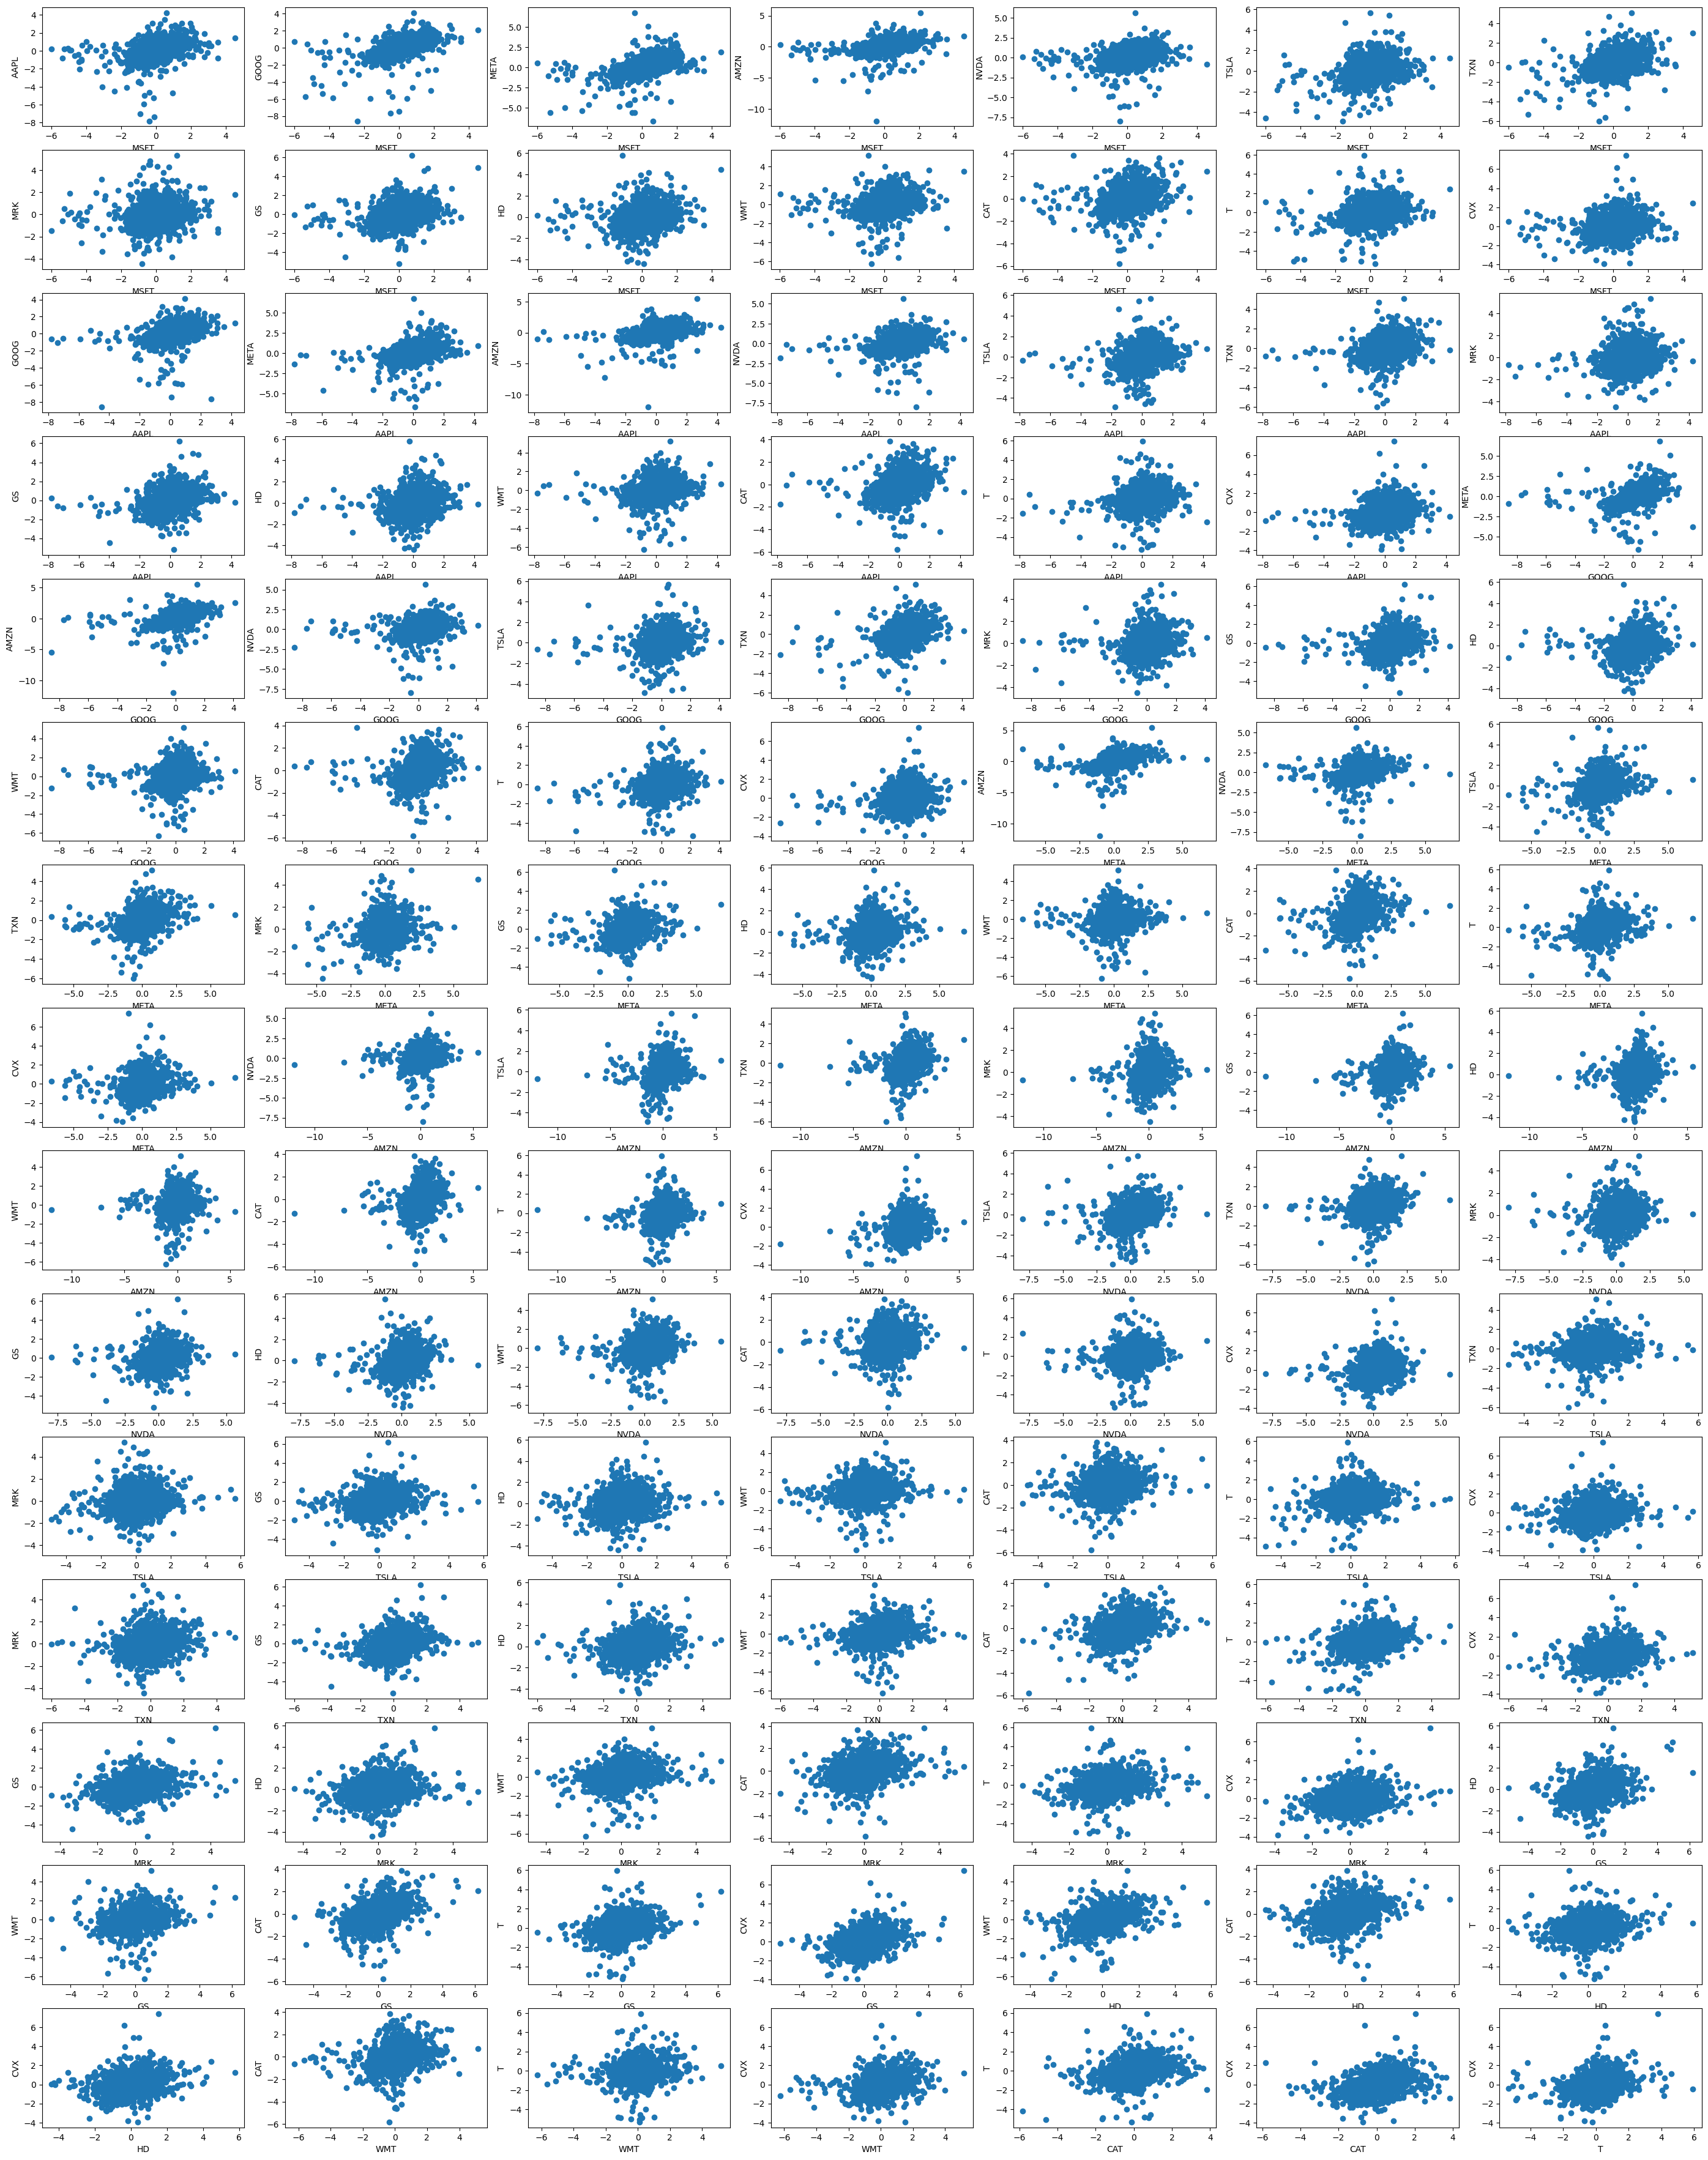

In [406]:
col_arrange = []
for key, val in sector_list.items():
    if key == "MAGS7":
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index))
    else:
        col_arrange.extend(list(mean_corr.loc[val].sort_values(ascending=False).index[:1]))

fig, axs = plt.subplots(15, 7, figsize=(35, 45))
i, j = 0, 0
for ticker_1, ticker_2 in combinations(col_arrange, 2):
    axs[i, j].scatter(resid_1fac[[ticker_1]], resid_1fac[[ticker_2]])
    axs[i, j].set_xlabel(ticker_1)
    axs[i, j].set_ylabel(ticker_2)
    j += 1
    if j==7:
        i += 1
        j = 0